In [2]:
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

# ❗ Өз жолыңызбен сәйкестендіріңіз (сіздің файлдарыңыз D: дискісінде)
PROJECT_ROOT = Path(r"D:\road_damage_yolo")
RAW_DIR = PROJECT_ROOT / "data" / "raw"
TRAIN_DIR = RAW_DIR / "rdd2020" / "train"
JAPAN_IMG_DIR = TRAIN_DIR / "Japan" / "images"
JAPAN_ANN_DIR = TRAIN_DIR / "Japan" / "annotations"

for name, p in [("Жоба", PROJECT_ROOT), ("Суреттер", JAPAN_IMG_DIR), ("Аннотациялар", JAPAN_ANN_DIR)]:
    print(f"{name:13s}: {p} | бар: {p.exists()}")

import sys
print("Python:", sys.executable)

Жоба         : D:\road_damage_yolo | бар: True
Суреттер     : D:\road_damage_yolo\data\raw\rdd2020\train\Japan\images | бар: True
Аннотациялар : D:\road_damage_yolo\data\raw\rdd2020\train\Japan\annotations | бар: True
Python: C:\Users\User\AppData\Local\Programs\Python\Python312\python.exe


Ұяшық 3.1. Көрші нөмірлі суреттер ұқсас па

Жапония суреттері: 10506 | алғашқысы: Japan_000000 | соңғысы: Japan_013132


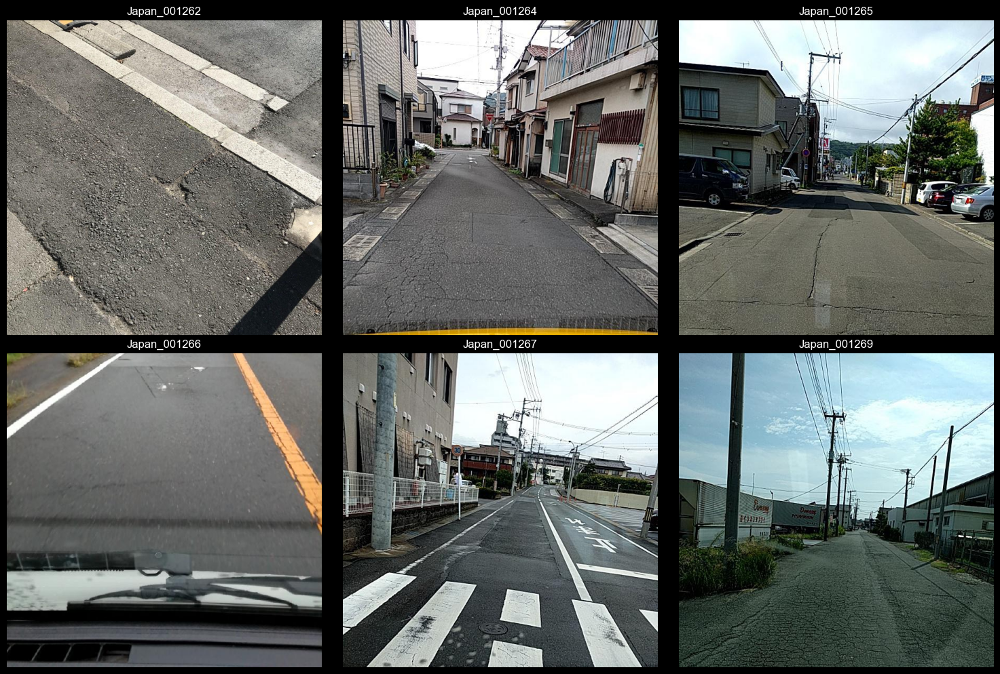

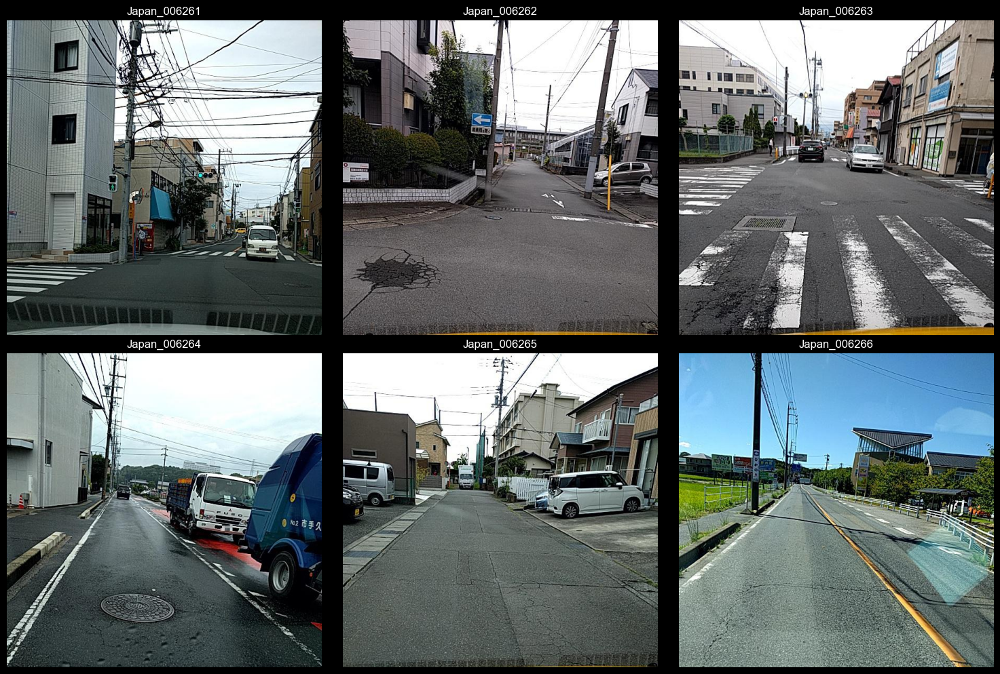

In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

PROJECT_ROOT = Path(r"D:\road_damage_yolo")      # өз жолыңызбен салыстырыңыз
RAW_DIR = PROJECT_ROOT / "data" / "raw"
TRAIN_DIR = RAW_DIR / "rdd2020" / "train"
JAPAN_IMG_DIR = TRAIN_DIR / "Japan" / "images"

jp_sorted = sorted(p.stem for p in JAPAN_IMG_DIR.glob("*.jpg"))
print("Жапония суреттері:", len(jp_sorted), "| алғашқысы:", jp_sorted[0], "| соңғысы:", jp_sorted[-1])

def show_seq(i0, n=6):
    chunk = jp_sorted[i0:i0 + n]
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    for ax, s in zip(axes.ravel(), chunk):
        ax.imshow(Image.open(JAPAN_IMG_DIR / f"{s}.jpg"))
        ax.set_title(s)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_seq(1000)
show_seq(5000)

Ұяшық 3.2. XML-ді YOLO белгілеріне түрлендіру (тек белгілер, әлі бөлмейміз)

In [4]:
import xml.etree.ElementTree as ET
import pandas as pd
from collections import Counter

if "xml_index" not in globals():
    xml_index = {p.stem: p for p in (TRAIN_DIR / "Japan" / "annotations").rglob("*.xml")}

STAGE_DIR = PROJECT_ROOT / "data" / "yolo_stage"
LABEL_DIR = STAGE_DIR / "labels"
LABEL_DIR.mkdir(parents=True, exist_ok=True)

CLASS_MAP = {"D00": 0, "D10": 1, "D20": 2, "D40": 3}
jp_stems = sorted(s for s in xml_index if s.startswith("Japan_"))
print("Жапония XML:", len(jp_stems))

rows, box_cnt = [], Counter()
n_clipped = n_invalid = n_size_mismatch = 0

for stem in jp_stems:
    root = ET.parse(xml_index[stem]).getroot()
    with Image.open(JAPAN_IMG_DIR / f"{stem}.jpg") as im:
        W, H = im.size
    if (int(root.findtext("size/width")), int(root.findtext("size/height"))) != (W, H):
        n_size_mismatch += 1

    lines, per_img, n_xml_target, n_other = [], Counter(), 0, 0
    for o in root.findall("object"):
        name = (o.findtext("name") or "").strip()
        if name not in CLASS_MAP:
            n_other += 1
            continue
        n_xml_target += 1
        bb = o.find("bndbox")
        x1, y1, x2, y2 = [float(bb.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")]
        c1, d1, c2, d2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
        if (c1, d1, c2, d2) != (x1, y1, x2, y2):
            n_clipped += 1
        if c2 <= c1 or d2 <= d1:
            n_invalid += 1
            continue
        lines.append(f"{CLASS_MAP[name]} {(c1+c2)/2/W:.6f} {(d1+d2)/2/H:.6f} {(c2-c1)/W:.6f} {(d2-d1)/H:.6f}")
        per_img[name] += 1

    if n_xml_target == 0 and n_other > 0:
        status = "only_other"
    elif n_xml_target > 0 and not lines:
        status = "bad_geometry"
    else:
        status = "kept_target" if lines else "kept_negative"
        (LABEL_DIR / f"{stem}.txt").write_text("\n".join(lines) + ("\n" if lines else ""), encoding="utf-8")
        box_cnt.update(per_img)

    rows.append(dict(stem=stem, W=W, H=H, n_valid=len(lines), n_other=n_other, status=status))

man = pd.DataFrame(rows)
man.to_csv(STAGE_DIR / "manifest_japan.csv", index=False)

print("\nСтатус бойынша суреттер:\n", man.status.value_counts())
print("\nСақталған қораптар (класс бойынша):", dict(box_cnt))
print("XML мен нақты сурет өлшемінің сәйкес еместігі:", n_size_mismatch)
print("Шекке қиылған қораптар:", n_clipped, "| жарамсыз қораптар:", n_invalid)
print("Сурет өлшемдері:\n", man.groupby(["W", "H"]).size())
print("Жазылған .txt файлдар саны:", len(list(LABEL_DIR.glob("*.txt"))))

Жапония XML: 10506

Статус бойынша суреттер:
 status
kept_target      7900
only_other       1812
kept_negative     794
Name: count, dtype: int64

Сақталған қораптар (класс бойынша): {'D20': 6198, 'D40': 2243, 'D10': 3979, 'D00': 4049}
XML мен нақты сурет өлшемінің сәйкес еместігі: 0
Шекке қиылған қораптар: 0 | жарамсыз қораптар: 1
Сурет өлшемдері:
 W     H   
540   540       124
600   600     10187
1024  1024      147
1080  1080       48
dtype: int64
Жазылған .txt файлдар саны: 8694


Ұяшық 3.3. XML ішінде орын/бейне ақпараты бар ма

In [5]:
one = sorted(JAPAN_ANN_DIR.rglob("*.xml"))[0]
print(one)
print(one.read_text(encoding="utf-8")[:1200])

D:\road_damage_yolo\data\raw\rdd2020\train\Japan\annotations\xmls\Japan_000000.xml
<annotation>
	<folder>images</folder>
	<filename>Japan_000000.jpg</filename>
	<size>
		<width>600</width>
		<height>600</height>
		<depth>3</depth>
	</size>
	<segmented>0</segmented>
	<object>
		<name>D20</name>
		<pose>Unspecified</pose>
		<truncated>1</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>406</xmin>
			<ymin>475</ymin>
			<xmax>600</xmax>
			<ymax>596</ymax>
		</bndbox>
	</object>
	<object>
		<name>D40</name>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>409</xmin>
			<ymin>373</ymin>
			<xmax>598</xmax>
			<ymax>472</ymax>
		</bndbox>
	</object>
	<object>
		<name>D10</name>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>394</xmin>
			<ymin>518</ymin>
			<xmax>557</xmax>
			<ymax>554</ymax>
		</bndbox>
	</object>
	<object>
		<name>D00</name>
		<pose>Unspecified</pose>
		<tru

Ұяшық 3.4. Бөлу, көшіру, data.yaml

In [6]:
import shutil, yaml
from collections import Counter

STAGE_DIR = PROJECT_ROOT / "data" / "yolo_stage"
LABEL_DIR = STAGE_DIR / "labels"
OUT = PROJECT_ROOT / "data" / "yolo_dataset"
SEED = 42

man = pd.read_csv(STAGE_DIR / "manifest_japan.csv")
keep = man[man.status.isin(["kept_target", "kept_negative"])].copy()
print("Прототип суреттері:", len(keep))

parts = []
for status, g in keep.groupby("status"):
    g = g.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
    n_val, n_test = round(len(g) * 0.10), round(len(g) * 0.10)
    g["split"] = "train"
    g.loc[:n_val - 1, "split"] = "val"
    g.loc[n_val:n_val + n_test - 1, "split"] = "test"
    parts.append(g)
split_df = pd.concat(parts, ignore_index=True)
split_df.to_csv(STAGE_DIR / f"split_seed{SEED}.csv", index=False)
print(split_df.groupby(["split", "status"]).size().unstack(fill_value=0))

# Әр жиын бойынша қорап саны
def box_counts(stem):
    c = Counter()
    for line in (LABEL_DIR / f"{stem}.txt").read_text().splitlines():
        if line.strip():
            c[int(line.split()[0])] += 1
    return c

rows = []
for r in split_df.itertuples():
    c = box_counts(r.stem)
    rows.append({"split": r.split, **{k: c.get(k, 0) for k in range(4)}})
box_table = pd.DataFrame(rows).groupby("split").sum()
box_table.columns = ["D00", "D10", "D20", "D40"]
print("\nҚорап саны:\n", box_table)
print("\nКласс үлесі (%):\n", (box_table.div(box_table.sum(axis=1), axis=0) * 100).round(1))

# Көшіру
if OUT.exists():
    shutil.rmtree(OUT)
for s in ["train", "val", "test"]:
    (OUT / "images" / s).mkdir(parents=True)
    (OUT / "labels" / s).mkdir(parents=True)
for r in split_df.itertuples():
    shutil.copy2(JAPAN_IMG_DIR / f"{r.stem}.jpg", OUT / "images" / r.split / f"{r.stem}.jpg")
    shutil.copy2(LABEL_DIR / f"{r.stem}.txt", OUT / "labels" / r.split / f"{r.stem}.txt")

# data.yaml
cfg = {"path": OUT.as_posix(), "train": "images/train", "val": "images/val", "test": "images/test",
       "names": {0: "D00", 1: "D10", 2: "D20", 3: "D40"}}
(PROJECT_ROOT / "configs").mkdir(exist_ok=True)
yaml_path = PROJECT_ROOT / "configs" / "data.yaml"
yaml_path.write_text(yaml.safe_dump(cfg, sort_keys=False), encoding="utf-8")
print("\n✅ data.yaml:", yaml_path)
print(yaml_path.read_text(encoding="utf-8"))

for s in ["train", "val", "test"]:
    ni = len(list((OUT / "images" / s).glob("*.jpg")))
    nl = len(list((OUT / "labels" / s).glob("*.txt")))
    print(f"{s:6s} сурет: {ni} | белгі: {nl}")

Прототип суреттері: 8694
status  kept_negative  kept_target
split                             
test               79          790
train             636         6320
val                79          790

Қорап саны:
         D00   D10   D20   D40
split                        
test    391   404   610   244
train  3269  3130  5023  1789
val     389   445   565   210

Класс үлесі (%):
         D00   D10   D20   D40
split                        
test   23.7  24.5  37.0  14.8
train  24.7  23.7  38.0  13.5
val    24.2  27.7  35.1  13.1

✅ data.yaml: D:\road_damage_yolo\configs\data.yaml
path: D:/road_damage_yolo/data/yolo_dataset
train: images/train
val: images/val
test: images/test
names:
  0: D00
  1: D10
  2: D20
  3: D40

train  сурет: 6956 | белгі: 6956
val    сурет: 869 | белгі: 869
test   сурет: 869 | белгі: 869


Ұяшық 3.5. Белгілерді аудит және визуалды тексеру

Қате жолдар: 0 []
Барлық қорап (0=D00, 1=D10, 2=D20, 3=D40): {1: 3979, 2: 6198, 0: 4049, 3: 2243} | қосынды: 16469


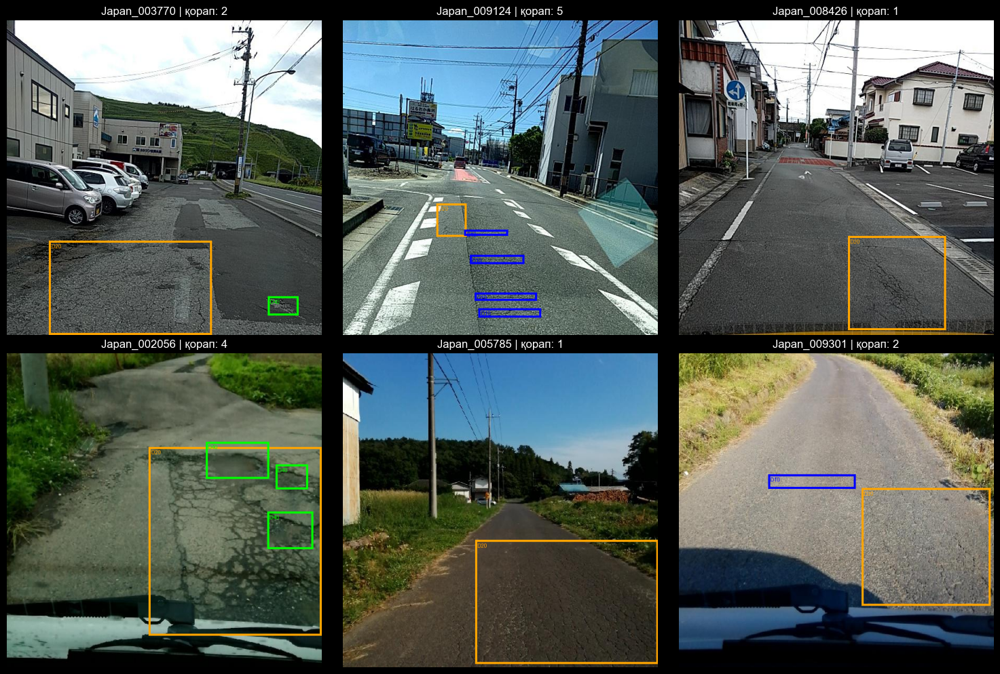

In [7]:
import random
from PIL import ImageDraw

bad, total = [], Counter()
for s in ["train", "val", "test"]:
    for f in (OUT / "labels" / s).glob("*.txt"):
        for ln, line in enumerate(f.read_text().splitlines()):
            p = line.split()
            ok = len(p) == 5 and p[0] in {"0", "1", "2", "3"}
            if ok:
                v = [float(x) for x in p[1:]]
                ok = all(0 <= x <= 1 for x in v) and v[2] > 0 and v[3] > 0
            if ok:
                total[int(p[0])] += 1
            else:
                bad.append((s, f.name, ln, line))
print("Қате жолдар:", len(bad), bad[:3])
print("Барлық қорап (0=D00, 1=D10, 2=D20, 3=D40):", dict(total), "| қосынды:", sum(total.values()))

random.seed(3)
colors = {0: "red", 1: "blue", 2: "orange", 3: "lime"}
names = {0: "D00", 1: "D10", 2: "D20", 3: "D40"}
stems = random.sample(sorted(p.stem for p in (OUT / "images" / "train").glob("*.jpg")), 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, stem in zip(axes.ravel(), stems):
    im = Image.open(OUT / "images" / "train" / f"{stem}.jpg").convert("RGB")
    W, H_ = im.size
    d = ImageDraw.Draw(im)
    n = 0
    for line in (OUT / "labels" / "train" / f"{stem}.txt").read_text().splitlines():
        c, xc, yc, w, h = line.split()
        c, xc, yc, w, h = int(c), float(xc) * W, float(yc) * H_, float(w) * W, float(h) * H_
        d.rectangle([xc - w/2, yc - h/2, xc + w/2, yc + h/2], outline=colors[c], width=4)
        d.text((xc - w/2 + 4, yc - h/2 + 4), names[c], fill=colors[c])
        n += 1
    ax.imshow(im); ax.set_title(f"{stem} | қорап: {n}"); ax.axis("off")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "figures" / "yolo_labels_check.png", dpi=120)
plt.show()

Ұяшық 3.6. Бөлінген жиындар арасындағы жуық көшірмелер (leakage тексеру)

val: ең жақын train суретіне қашықтық | медиана=14, min=1, ≤5: 5, ≤10: 90 (барлығы 869)
test: ең жақын train суретіне қашықтық | медиана=14, min=0, ≤5: 13, ≤10: 93 (барлығы 869)


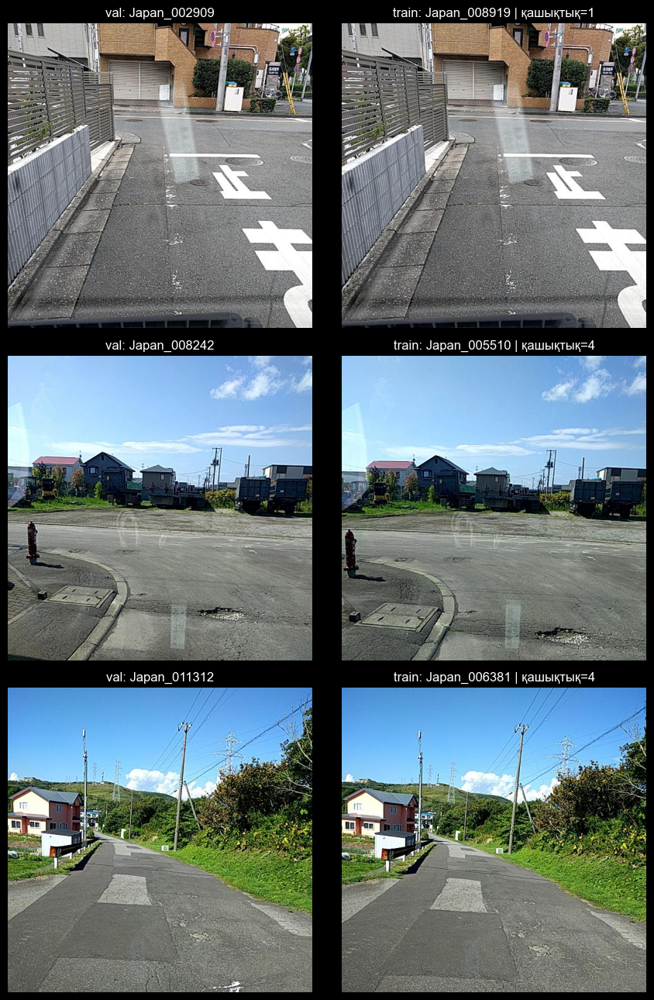

In [8]:
import numpy as np

def dhash(path, size=8):
    with Image.open(path) as im:
        g = im.convert("L").resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(g, dtype=np.int16)
    return np.packbits((a[:, 1:] > a[:, :-1]).flatten())   # 8 байт

paths = {s: sorted((OUT / "images" / s).glob("*.jpg")) for s in ["train", "val", "test"]}
Hs = {s: np.stack([dhash(p) for p in paths[s]]) for s in paths}
POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

def min_dist(query, ref):
    dist, arg = np.empty(len(query), dtype=np.int32), np.empty(len(query), dtype=np.int32)
    for i, q in enumerate(query):
        d = POP[np.bitwise_xor(ref, q)].sum(axis=1)
        arg[i] = d.argmin(); dist[i] = d[arg[i]]
    return dist, arg

res = {}
for s in ["val", "test"]:
    res[s] = min_dist(Hs[s], Hs["train"])
    d = res[s][0]
    print(f"{s}: ең жақын train суретіне қашықтық | медиана={np.median(d):.0f}, "
          f"min={d.min()}, ≤5: {(d <= 5).sum()}, ≤10: {(d <= 10).sum()} (барлығы {len(d)})")

d, a = res["val"]
idx = np.argsort(d)[:3]
fig, axes = plt.subplots(3, 2, figsize=(9, 13))
for row, i in enumerate(idx):
    axes[row][0].imshow(Image.open(paths["val"][i])); axes[row][0].set_title(f"val: {paths['val'][i].stem}")
    axes[row][1].imshow(Image.open(paths["train"][a[i]])); axes[row][1].set_title(f"train: {paths['train'][a[i]].stem} | қашықтық={d[i]}")
    axes[row][0].axis("off"); axes[row][1].axis("off")
plt.tight_layout()
plt.show()

Ұяшық 3.7. Жұптарды көру

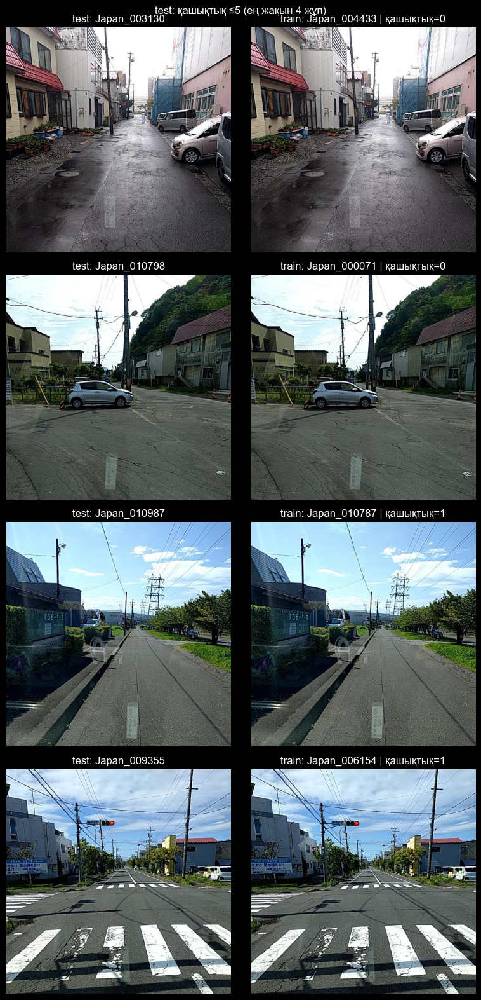

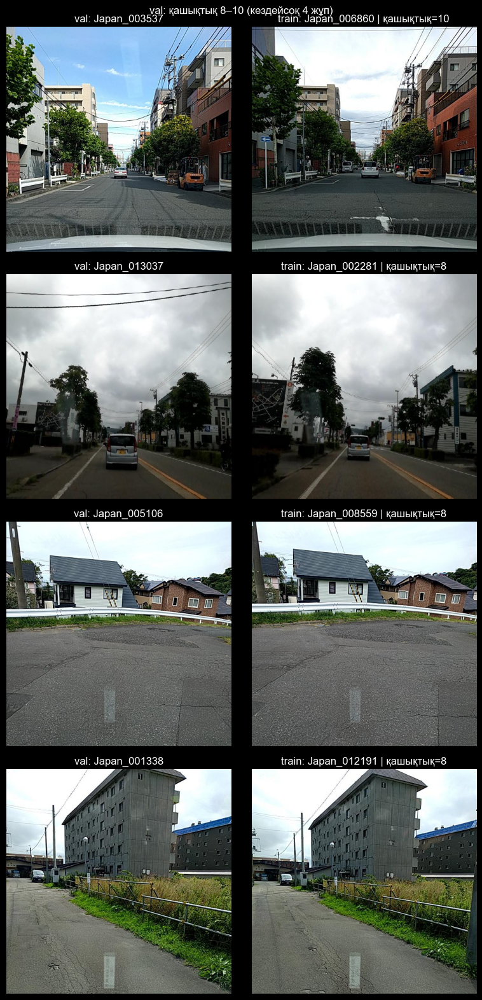

In [9]:
import numpy as np

d_val, a_val = res["val"]
d_te, a_te = res["test"]

def show_pairs(split, d, a, idx, title):
    idx = list(idx)[:4]
    fig, axes = plt.subplots(len(idx), 2, figsize=(8, 4 * len(idx)), squeeze=False)
    for r, i in enumerate(idx):
        axes[r][0].imshow(Image.open(paths[split][i]))
        axes[r][0].set_title(f"{split}: {paths[split][i].stem}")
        axes[r][1].imshow(Image.open(paths["train"][a[i]]))
        axes[r][1].set_title(f"train: {paths['train'][a[i]].stem} | қашықтық={d[i]}")
        axes[r][0].axis("off"); axes[r][1].axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

close_te = np.where(d_te <= 5)[0]
show_pairs("test", d_te, a_te, close_te[np.argsort(d_te[close_te])],
           "test: қашықтық ≤5 (ең жақын 4 жұп)")

rng = np.random.default_rng(0)
mid_val = np.where((d_val >= 8) & (d_val <= 10))[0]
show_pairs("val", d_val, a_val, rng.permutation(mid_val),
           "val: қашықтық 8–10 (кездейсоқ 4 жұп)")

Ұяшық 3.8. Жуық көшірмелерді алып тастау

In [10]:
drop = []
for s, (d, a) in res.items():
    for i in np.where(d <= 5)[0]:
        drop.append((s, paths[s][i].stem, int(d[i]), paths["train"][a[i]].stem))

drop_df = pd.DataFrame(drop, columns=["split", "stem", "dist", "nearest_train"])
drop_df.to_csv(STAGE_DIR / "dropped_near_duplicates.csv", index=False)

for r in drop_df.itertuples():
    (OUT / "images" / r.split / f"{r.stem}.jpg").unlink(missing_ok=True)
    (OUT / "labels" / r.split / f"{r.stem}.txt").unlink(missing_ok=True)

print("Алынған суреттер:\n", drop_df.split.value_counts())
for s in ["train", "val", "test"]:
    ni = len(list((OUT / "images" / s).glob("*.jpg")))
    nl = len(list((OUT / "labels" / s).glob("*.txt")))
    print(f"{s:6s} сурет: {ni} | белгі: {nl}")

Алынған суреттер:
 split
test    13
val      5
Name: count, dtype: int64
train  сурет: 6956 | белгі: 6956
val    сурет: 864 | белгі: 864
test   сурет: 856 | белгі: 856
